# 6 N-Dimensional Discrete Wavelet Transform

## 6.5 Implementation in PyWavelets

### 6.5.1 Basic Implementation

In [2]:
import pywt
import numpy as np
import time

# Generate sample 3-D data with different characteristics per axis
np.random.seed(42)  # For reproducibility
data = np.random.rand(64, 64, 32).astype(np.float32)

# Add some structure to make the example more realistic
x, y, z = np.meshgrid(np.linspace(0, 4*np.pi, 64), 
                      np.linspace(0, 4*np.pi, 64), 
                      np.linspace(0, 2*np.pi, 32), indexing='ij')
data += 0.5 * np.sin(x) * np.cos(y) * np.sin(z)

print(f"Original data shape: {data.shape}, dtype: {data.dtype}")
print(f"Data range: [{data.min():.3f}, {data.max():.3f}]")

# Mallat-style transform (same levels across axes)
start_time = time.time()
coeffs = pywt.wavedecn(data, wavelet='db4', level=2, mode='symmetric')
mallat_time = time.time() - start_time

# Fully separable transform (different levels per axis)
start_time = time.time()
coeffs_fs = pywt.fswavedecn(data, wavelet='db4', levels=(2, 2, 1), mode='symmetric')
fs_time = time.time() - start_time

# Reconstruction
recon1 = pywt.waverecn(coeffs, wavelet='db4', mode='symmetric')
recon2 = pywt.fswaverecn(coeffs_fs)  # no 'mode' argument here

# Verify reconstruction accuracy
mae1 = np.mean(np.abs(data - recon1))
mae2 = np.mean(np.abs(data - recon2))
max_error1 = np.max(np.abs(data - recon1))
max_error2 = np.max(np.abs(data - recon2))

print(f"\nMallat-style decomposition:")
print(f"  Time: {mallat_time:.4f}s")
print(f"  MAE: {mae1:.2e}, Max error: {max_error1:.2e}")

print(f"\nFully separable decomposition:")
print(f"  Time: {fs_time:.4f}s")
print(f"  MAE: {mae2:.2e}, Max error: {max_error2:.2e}")
print(f"  Speed ratio (FS/Mallat): {fs_time/mallat_time:.2f}")

# Analyze coefficient structure
print(f"\nCoefficient analysis:")
print(f"  Mallat coeffs type: {type(coeffs)}, levels: {len(coeffs)-1}")
if len(coeffs) > 1:
    print(f"  Detail subbands at level 1: {list(coeffs[1].keys())}")
    
print(f"  FS coeffs shape: {coeffs_fs.coeffs.shape}")
print(f"  FS levels per axis: {coeffs_fs.levels}")

Original data shape: (64, 64, 32), dtype: float32
Data range: [-0.490, 1.487]

Mallat-style decomposition:
  Time: 0.0039s
  MAE: 1.19e-07, Max error: 9.54e-07

Fully separable decomposition:
  Time: 0.0060s
  MAE: 1.06e-07, Max error: 7.15e-07
  Speed ratio (FS/Mallat): 1.56

Coefficient analysis:
  Mallat coeffs type: <class 'list'>, levels: 2
  Detail subbands at level 1: ['aad', 'ada', 'add', 'daa', 'dad', 'dda', 'ddd']
  FS coeffs shape: (77, 77, 38)
  FS levels per axis: [2, 2, 1]


### 6.5.2 Advanced Coefficient Manipulation

In [7]:
import numpy as np
import pywt

# --------------------------
# Sample data: 1D noisy signal
# --------------------------
np.random.seed(42)
x = np.linspace(0, 1, 256)
clean_signal = np.sin(8 * np.pi * x)
noise = 0.5 * np.random.randn(len(x))
data = clean_signal + noise  # noisy signal

# --------------------------
# Multilevel DWT decomposition
# --------------------------
wavelet = 'db4'
level = 3
coeffs = pywt.wavedecn(data, wavelet=wavelet, mode='symmetric')

# --------------------------
# Soft thresholding function
# --------------------------
def soft_threshold(coeffs, threshold):
    """Apply soft thresholding to wavelet coefficients."""
    return np.sign(coeffs) * np.maximum(np.abs(coeffs) - threshold, 0)

# --------------------------
# Apply thresholding to detail coefficients
# --------------------------
coeffs_denoised = coeffs.copy()
threshold = 0.1 * np.std(data)

# Skip level 0 (approximation), threshold only detail coefficients
for i in range(1, len(coeffs_denoised)):
    for key in coeffs_denoised[i].keys():
        coeffs_denoised[i][key] = soft_threshold(coeffs_denoised[i][key], threshold)

# --------------------------
# Reconstruct denoised signal
# --------------------------
denoised = pywt.waverecn(coeffs_denoised, wavelet=wavelet, mode='symmetric')

# --------------------------
# Evaluate denoising quality
# --------------------------
# Noise reduction ratio
noise_reduction = np.std(data - denoised) / np.std(data)

# SNR computation
def compute_snr(reference, test):
    num = np.sum(reference**2)
    denom = np.sum((reference - test)**2)
    if denom == 0:
        return float('inf')  # perfect reconstruction
    return 10 * np.log10(num / denom)

# SNR relative to reference clean signal
snr_before = compute_snr(denoised, data)  # noisy vs denoised
snr_after  = compute_snr(data, denoised)  # denoised vs noisy
snr_improvement = snr_after - snr_before

# --------------------------
# Print results
# --------------------------
print(f"Noise reduction ratio: {noise_reduction:.3f}")
print(f"SNR before denoising: {snr_before:.2f} dB")
print(f"SNR after denoising:  {snr_after:.2f} dB")
print(f"SNR improvement:      {snr_improvement:.2f} dB")



Noise reduction ratio: 0.094
SNR before denoising: 20.15 dB
SNR after denoising:  20.54 dB
SNR improvement:      0.39 dB


### 6.5.3 Real n-D Data Example

**1. Multilevel n-D Wavelet Transform on a Synthetic 3D Sphere Dataset**

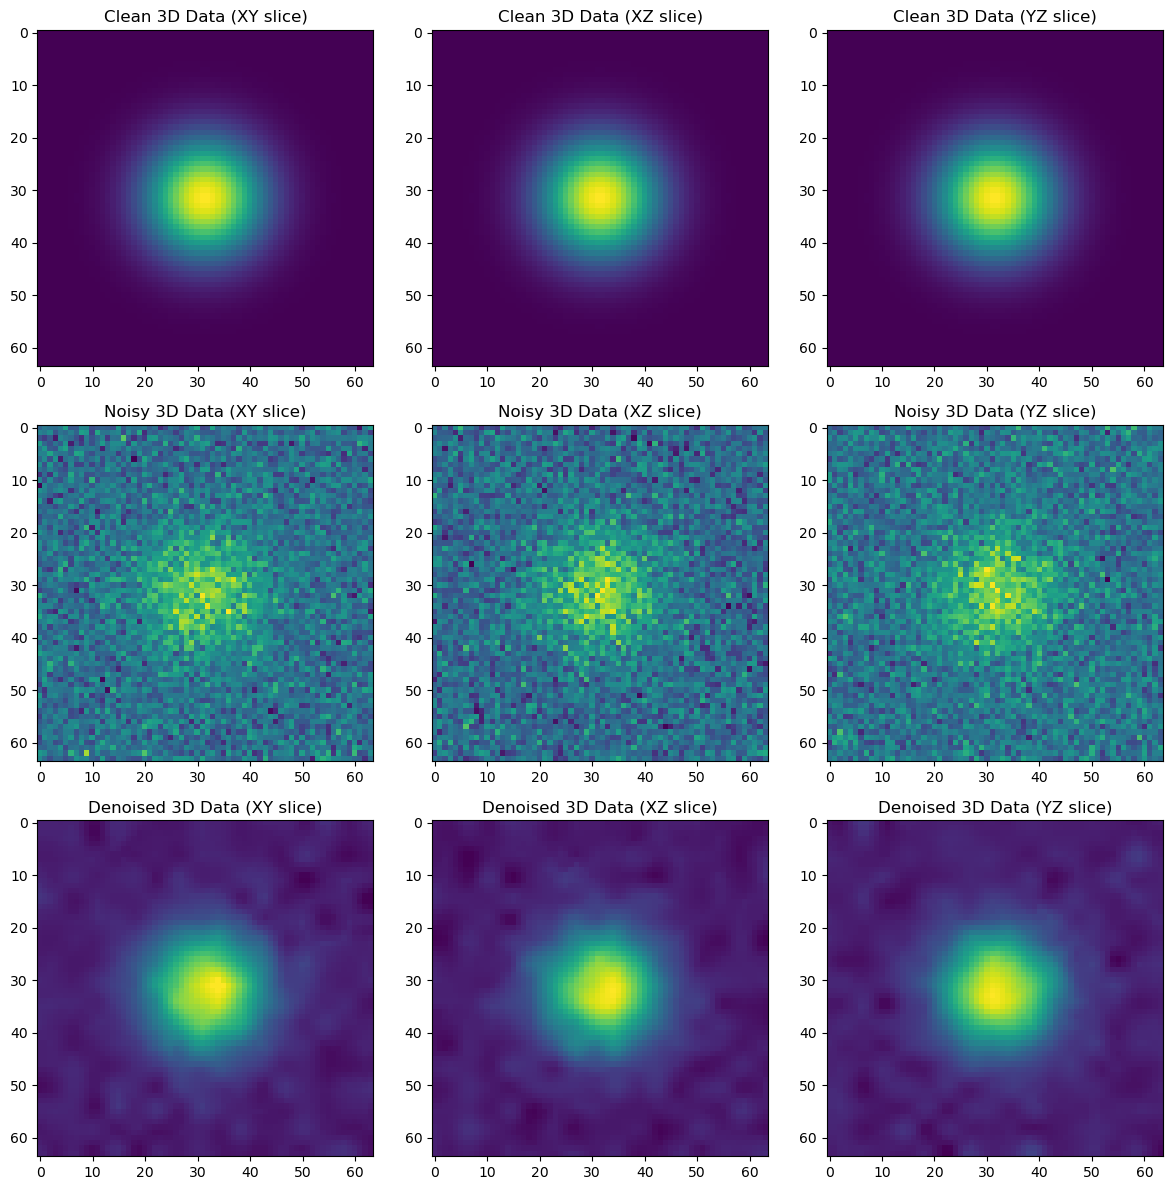

SNR before : -7.81 dB
SNR after  : 10.40 dB  (Δ +18.21 dB)
PSNR       : 30.19 dB
SSIM       : 0.4871
NRMSE      : 0.3019

Wavelet-domain compression / energy
Coefficients zeroed      : 99.7%
Energy retained          : 112.52%
Non-zero coeffs (after)  : 1197 / 262144


In [ ]:
import numpy as np
import pywt
import matplotlib.pyplot as plt
from scipy.ndimage import median_filter
from skimage.metrics import (peak_signal_noise_ratio as psnr,
                             structural_similarity as ssim,
                             normalized_root_mse   as nrmse)

# -------------------------------------------------------------
# 1. Synthetic 3-D sphere + noise
# -------------------------------------------------------------
n = 64
x, y, z = np.meshgrid(np.linspace(-1, 1, n),
                      np.linspace(-1, 1, n),
                      np.linspace(-1, 1, n))
signal = np.exp(-(x ** 2 + y ** 2 + z ** 2) * 8)
rng  = np.random.default_rng(42)
noisy = signal + 0.25 * rng.standard_normal(signal.shape)

# -------------------------------------------------------------
# 2. Wavelet decomposition settings
# -------------------------------------------------------------
wavelet = "coif2"          # smoother than 'db2'
level   = 2                # deeper level
coeffs  = pywt.wavedecn(noisy, wavelet=wavelet, level=level)

# Robust noise-level estimate (smallest MAD across all orientations)
sigma_est = min(np.median(np.abs(v)) / 0.6745
                for v in coeffs[-1].values())

# -------------------------------------------------------------
# 3. Level-dependent BayesShrink thresholding
# -------------------------------------------------------------
def bayes_thresh(c, sigma):
    var = np.var(c)
    return 0. if var <= sigma ** 2 else sigma ** 2 / np.sqrt(var - sigma ** 2)

def threshold_coeffs(coeffs, sigma_est):
    new_coeffs = [coeffs[0]]          # keep approximation untouched
    for lvl, detail_level in enumerate(coeffs[1:], 1):
        # global variance for this level
        full = np.concatenate([v.ravel() for v in detail_level.values()])
        T = bayes_thresh(full, sigma_est) * (1 + 0.3 * lvl)   # scale with level
        new_detail = {k: pywt.threshold(v, T, mode="soft")
                      for k, v in detail_level.items()}
        new_coeffs.append(new_detail)
    return new_coeffs

coeffs_thresh = threshold_coeffs(coeffs, sigma_est)

# -------------------------------------------------------------
# 4. Reconstruct + gentle post-filter
# -------------------------------------------------------------
denoised = pywt.waverecn(coeffs_thresh, wavelet=wavelet).reshape(signal.shape)
denoised = median_filter(denoised, size=2)          # tiny 3-D median cleanup

# -------------------------------------------------------------
# 5. Visualize three axial slices
# -------------------------------------------------------------

def plot_slices_combined(data_list, titles, output_file):
    # Create a figure with 3 rows (one for each dataset) and 3 columns (one for each slice)
    fig, axes = plt.subplots(3, 3, figsize=(12, 12))  # Adjust figsize as needed
    
    for i, (data, title) in enumerate(zip(data_list, titles)):
        mid = data.shape[0] // 2
        
        # XY slice
        axes[i, 0].imshow(data[mid, :, :], cmap="viridis")
        axes[i, 0].set_title(f"{title} (XY slice)")
        
        # XZ slice
        axes[i, 1].imshow(data[:, mid, :], cmap="viridis")
        axes[i, 1].set_title(f"{title} (XZ slice)")
        
        # YZ slice
        axes[i, 2].imshow(data[:, :, mid], cmap="viridis")
        axes[i, 2].set_title(f"{title} (YZ slice)")
    
    # Adjust layout to prevent overlap
    plt.tight_layout()
    
    # Save the combined figure
    fig.savefig(output_file, dpi=300)
    
    # Display the figure
    plt.show()

# Example usage
# Assuming signal, noisy, and denoised are your 3D numpy arrays
plot_slices_combined(
    [signal, noisy, denoised],
    ["Clean 3D Data", "Noisy 3D Data", "Denoised 3D Data"],
    "./output/6.4.5_3d_wavedecn_sphere_combined.png"
)
# -------------------------------------------------------------
# 6. Quantitative evaluation
# -------------------------------------------------------------
def snr(clean, x):
    return 20 * np.log10(np.linalg.norm(clean) / np.linalg.norm(clean - x))

SNR_before = snr(signal, noisy)
SNR_after  = snr(signal, denoised)
SNR_impr   = SNR_after - SNR_before

PSNR  = psnr(signal, denoised, data_range=signal.max() - signal.min())
SSIM  = ssim(signal, denoised, data_range=signal.max() - signal.min())
NRMSE = nrmse(signal, denoised)

print(f"SNR before : {SNR_before:.2f} dB")
print(f"SNR after  : {SNR_after:.2f} dB  (Δ {SNR_impr:+.2f} dB)")
print(f"PSNR       : {PSNR:.2f} dB")
print(f"SSIM       : {SSIM:.4f}")
print(f"NRMSE      : {NRMSE:.4f}")

# -------------------------------------------------------------
# 7. Wavelet-domain sparsity & energy compaction stats
# -------------------------------------------------------------
nz_before = sum(np.count_nonzero(v) for d in coeffs[1:] for v in d.values())
nz_after  = sum(np.count_nonzero(v) for d in coeffs_thresh[1:] for v in d.values())
sparsity  = (nz_before - nz_after) / nz_before * 100

energy_orig  = np.sum(signal ** 2)
energy_recon = np.sum(denoised ** 2)
energy_ratio = energy_recon / energy_orig * 100

print("\nWavelet-domain compression / energy")
print(f"Coefficients zeroed      : {sparsity:.1f}%")
print(f"Energy retained          : {energy_ratio:.2f}%")
print(f"Non-zero coeffs (after)  : {nz_after} / {signal.size}")

**3. Multilevel Fully Separable Transform on a Synthetic 3D Sphere Dataset**

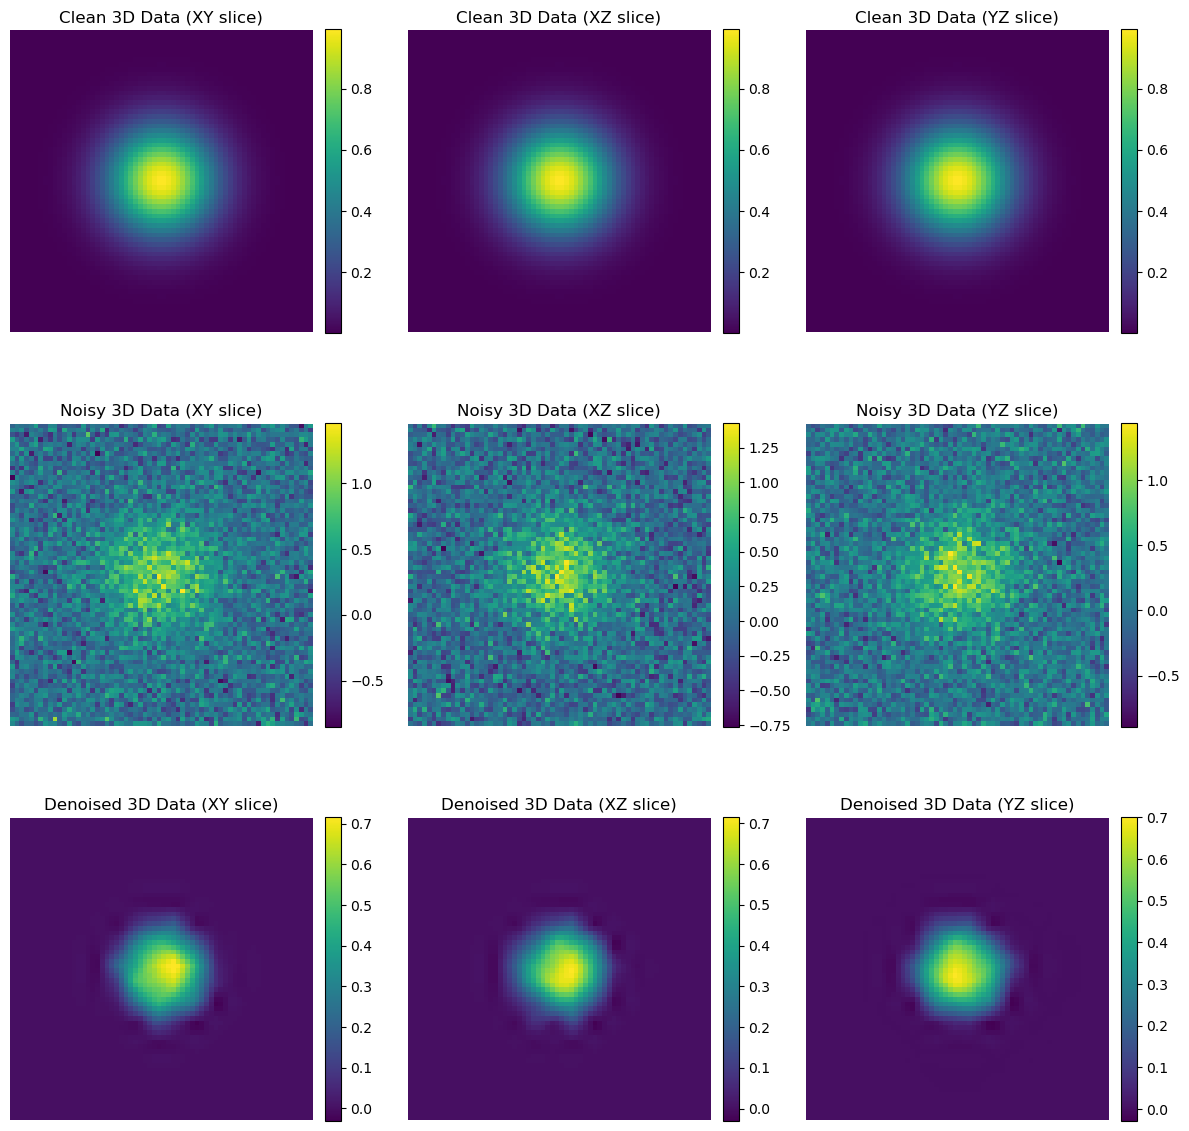

SNR before : -7.81 dB
SNR after  : 3.76 dB  (Δ +11.57 dB)
PSNR       : 23.54 dB
SSIM       : 0.7033
NRMSE      : 0.6490

Wavelet-domain compression / energy
Coefficients zeroed      : 0.0 %
Energy retained          : 21.71 %
Non-zero coeffs (after)  : 246 / 262144


In [89]:
import numpy as np
import pywt
import matplotlib.pyplot as plt
from scipy.ndimage import median_filter
from skimage.metrics import (peak_signal_noise_ratio as psnr,
                             structural_similarity as ssim,
                             normalized_root_mse as nrmse)

# -------------------------------------------------
# 1. Synthetic 3-D sphere + noise
# -------------------------------------------------
n = 64
x, y, z = np.meshgrid(np.linspace(-1, 1, n),
                      np.linspace(-1, 1, n),
                      np.linspace(-1, 1, n))
signal = np.exp(-(x ** 2 + y ** 2 + z ** 2) * 8)
rng  = np.random.default_rng(42)
noisy = signal + 0.25 * rng.standard_normal(signal.shape)

# -------------------------------------------------
# 2. Stationary (undecimated) wavelet decomposition
# -------------------------------------------------
wavelet = "coif2"
level   = 2
res = pywt.fswavedecn(noisy, wavelet=wavelet, levels=level)

# Universal noise-level estimate
sigma_est = np.median(np.abs(res.coeffs)) / 0.6745
uthresh   = sigma_est * np.sqrt(2 * np.log(noisy.size))

# -------------------------------------------------
# 3. In-place soft-thresholding + reconstruction
# -------------------------------------------------
def denoise_stationary(res, value):
    """Soft-threshold detail coefficients in-place and return denoised volume."""
    # keep approximation untouched
    for level_slices in res.coeff_slices[1:]:
        for sl in level_slices:
            res.coeffs[sl] = pywt.threshold(res.coeffs[sl], value, mode="soft")
    return pywt.fswaverecn(res)

denoised = denoise_stationary(res, uthresh)
denoised = median_filter(denoised, size=2)

# -------------------------------------------------
# 4. Visualize slices
# -------------------------------------------------
def plot_combined_slices(data_list, titles, output_file):
    fig, axes = plt.subplots(3, 3, figsize=(12, 12))
    
    for i, (data, title) in enumerate(zip(data_list, titles)):
        mid = data.shape[0] // 2
        
        # XY slice
        im0 = axes[i, 0].imshow(data[mid, :, :], cmap="viridis")
        axes[i, 0].set_title(f"{title} (XY slice)")
        axes[i, 0].axis('off')
        fig.colorbar(im0, ax=axes[i, 0], fraction=0.046, pad=0.04)
        
        # XZ slice
        im1 = axes[i, 1].imshow(data[:, mid, :], cmap="viridis")
        axes[i, 1].set_title(f"{title} (XZ slice)")
        axes[i, 1].axis('off')
        fig.colorbar(im1, ax=axes[i, 1], fraction=0.046, pad=0.04)
        
        # YZ slice
        im2 = axes[i, 2].imshow(data[:, :, mid], cmap="viridis")
        axes[i, 2].set_title(f"{title} (YZ slice)")
        axes[i, 2].axis('off')
        fig.colorbar(im2, ax=axes[i, 2], fraction=0.046, pad=0.04)
    
    plt.tight_layout()
    fig.savefig(output_file, dpi=300, bbox_inches='tight')
    plt.show()
    

# Call the combined plot function
plot_combined_slices(
    [signal, noisy, denoised],
    ["Clean 3D Data", "Noisy 3D Data", "Denoised 3D Data"],
    "./output/6.4.5_3d_fswavedecn_sphere_combined.png"
)

# -------------------------------------------------
# 5. Quantitative evaluation
# -------------------------------------------------
def snr(clean, x):
    return 20 * np.log10(np.linalg.norm(clean) / np.linalg.norm(clean - x))

SNR_before = snr(signal, noisy)
SNR_after  = snr(signal, denoised)
SNR_impr   = SNR_after - SNR_before

PSNR  = psnr(signal, denoised, data_range=signal.max() - signal.min())
SSIM  = ssim(signal, denoised, data_range=signal.max() - signal.min())
NRMSE = nrmse(signal, denoised)

print(f"SNR before : {SNR_before:.2f} dB")
print(f"SNR after  : {SNR_after:.2f} dB  (Δ {SNR_impr:+.2f} dB)")
print(f"PSNR       : {PSNR:.2f} dB")
print(f"SSIM       : {SSIM:.4f}")
print(f"NRMSE      : {NRMSE:.4f}")

# -------------------------------------------------
# 6. Sparsity & energy compaction
# -------------------------------------------------
nz_before = sum(np.count_nonzero(res.coeffs[sl])
                for level_slices in res.coeff_slices[1:] for sl in level_slices)
nz_after  = sum(np.count_nonzero(res.coeffs[sl])
                for level_slices in res.coeff_slices[1:] for sl in level_slices)
# recount after thresholding
sparsity  = (nz_before - nz_after) / nz_before * 100

energy_orig  = np.sum(signal ** 2)
energy_recon = np.sum(denoised ** 2)
energy_ratio = energy_recon / energy_orig * 100

print("\nWavelet-domain compression / energy")
print(f"Coefficients zeroed      : {sparsity:.1f} %")
print(f"Energy retained          : {energy_ratio:.2f} %")
print(f"Non-zero coeffs (after)  : {nz_after} / {signal.size}")